## Local Model Inference & Hardware Profiler

In [1]:
# run model using python; Hugging Face Transformers + PyTorch + bitsandbytes

# sentencepiece --> support text processing for some models
%pip install -q transformers accelerate bitsandbytes sentencepiece

In [2]:
import torch
import transformers           # load and run the model
import accelerate             # manage model running on h/w
import bitsandbytes as bnb    # run model with less memory using 4-bit quantization

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bnb.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Free VRAM (GB):",
      round(torch.cuda.mem_get_info(0)[0] / 1024**3, 2))

PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Accelerate: 1.15.0
BitsAndBytes: 0.50.2
GPU: Tesla T4
Free VRAM (GB): 14.46


In [3]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    torch_dtype=torch.float16,
    device_map="auto",
)

model.eval()

print("Model loaded:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM allocated (GB):",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2))


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-7B-Instruct
GPU: Tesla T4
VRAM allocated (GB): 5.18


In [4]:
prompt = "Explain why measuring water resources is important."

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.inference_mode():
    output = model.generate(
        **inputs,
        max_new_tokens=40,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )

print(tokenizer.decode(output[0], skip_special_tokens=True))


Explain why measuring water resources is important. Measuring water resources is crucial for several reasons:

1. **Water Management and Allocation**: Accurate measurement of water resources helps in managing and allocating water efficiently among various sectors such as agriculture, industry,


## Python profiler
Generate tokens, one by one   
Record times of their generation, through a specific Streamer.  

We measure our reserved PyTorch memory


In [5]:
import time
import gc
import pandas as pd
import torch

from transformers.generation.streamers import BaseStreamer


class TimingStreamer(BaseStreamer):
    def __init__(self):
        self.timestamps = []
        self.first_put = True

    def put(self, value):
        # The first call contains the input prompt, not generated output.
        if self.first_put:
            self.first_put = False
            return

        self.timestamps.append(time.perf_counter())

    def end(self):
        pass


def make_prompt_ids(context_length):
    text = (
        "Water resources in Egypt depend on river flow, rainfall, "
        "groundwater, irrigation demand, and climate variability. "
    )
    base_ids = tokenizer.encode(text, add_special_tokens=False)

    repeats = (context_length // len(base_ids)) + 1
    ids = (base_ids * repeats)[:context_length]

    return torch.tensor([ids], dtype=torch.long, device=model.device)


def profile_once(context_length, max_new_tokens=32):
    input_ids = make_prompt_ids(context_length)
    attention_mask = torch.ones_like(input_ids)

    # Synchronize CUDA so timing starts after earlier GPU work finishes.
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    baseline_allocated = torch.cuda.memory_allocated()
    streamer = TimingStreamer()

    start = time.perf_counter()

    with torch.inference_mode():
        model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id,
            streamer=streamer,
        )

    torch.cuda.synchronize()
    end = time.perf_counter()

    total_seconds = end - start
    timestamps = streamer.timestamps
    generated_tokens = len(timestamps)

    ttft_seconds = (
        timestamps[0] - start if timestamps else float("nan")
    )

    intervals = [
        timestamps[i] - timestamps[i - 1]
        for i in range(1, len(timestamps))
    ]

    mean_inter_token_ms = (
        1000 * sum(intervals) / len(intervals)
        if intervals else float("nan")
    )

    generation_seconds = max(total_seconds - ttft_seconds, 1e-9)
    throughput = generated_tokens / generation_seconds

    peak_allocated = torch.cuda.max_memory_allocated()
    peak_reserved = torch.cuda.max_memory_reserved()

    return {
        "context_length": context_length,
        "generated_tokens": generated_tokens,
        "ttft_ms": ttft_seconds * 1000,
        "mean_inter_token_ms": mean_inter_token_ms,
        "throughput_tokens_per_sec": throughput,
        "total_request_seconds": total_seconds,
        "baseline_allocated_gb": baseline_allocated / 1024**3,
        "peak_allocated_gb": peak_allocated / 1024**3,
        "incremental_peak_gb": (
            peak_allocated - baseline_allocated
        ) / 1024**3,
        "peak_reserved_gb": peak_reserved / 1024**3,
    }


## The 4 required calculations

4 different contexts

In [7]:

# Warm-up: not included in the final measurements
_ = profile_once(128, max_new_tokens=8)

context_lengths = [1024, 2048, 4096, 8192]
repeats = 2

results = []

for context_length in context_lengths:
    for run_number in range(1, repeats + 1):
        print(f"Context={context_length}, run={run_number}")

        try:
            row = profile_once(context_length, max_new_tokens=32)
            row["run"] = run_number
            row["status"] = "success"
            row["error"] = ""
            results.append(row)

            pd.DataFrame(results).to_csv(
                "/content/profiling_results.csv", index=False
            )

            print(
                f"TTFT: {row['ttft_ms']:.1f} ms | "
                f"Throughput: {row['throughput_tokens_per_sec']:.2f} "
                "tokens/s | "
                f"Peak VRAM: {row['peak_allocated_gb']:.2f} GB"
            )

        except Exception as exc:
            message = str(exc)
            results.append({
                "context_length": context_length,
                "run": run_number,
                "status": "failed",
                "error": message[:500],
            })

            pd.DataFrame(results).to_csv(
                "/content/profiling_results.csv", index=False
            )

            print("Experiment failed:", message[:300])

            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
display(results_df)

Context=1024, run=1
TTFT: 931.0 ms | Throughput: 11.25 tokens/s | Peak VRAM: 5.58 GB
Context=1024, run=2
TTFT: 941.8 ms | Throughput: 6.84 tokens/s | Peak VRAM: 5.58 GB
Context=2048, run=1
TTFT: 2267.6 ms | Throughput: 14.83 tokens/s | Peak VRAM: 6.47 GB
Context=2048, run=2
TTFT: 2253.3 ms | Throughput: 15.20 tokens/s | Peak VRAM: 6.47 GB
Context=4096, run=1
TTFT: 6508.3 ms | Throughput: 10.43 tokens/s | Peak VRAM: 9.75 GB
Context=4096, run=2
TTFT: 6659.9 ms | Throughput: 10.37 tokens/s | Peak VRAM: 9.75 GB
Context=8192, run=1
Experiment failed: CUDA out of memory. Tried to allocate 7.00 GiB. GPU 0 has a total capacity of 14.56 GiB of which 895.81 MiB is free. Including non-PyTorch memory, this process has 13.69 GiB memory in use. Of the allocated memory 13.09 GiB is allocated by PyTorch, and 478.30 MiB is reserved by PyTorch but unallocate
Context=8192, run=2
Experiment failed: CUDA out of memory. Tried to allocate 7.00 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.17 GiB is

,context_length,generated_tokens,ttft_ms,mean_inter_token_ms,throughput_tokens_per_sec,total_request_seconds,baseline_allocated_gb,peak_allocated_gb,incremental_peak_gb,peak_reserved_gb,run,status,error
0,1024,32.0,930.951550,91.770858,11.246748,3.776219,5.186928,5.578498,0.391570,5.628906,1,success,
1,1024,32.0,941.755390,150.904778,6.839899,5.620187,5.186928,5.578498,0.391570,5.628906,2,success,
2,2048,32.0,2267.550012,69.610895,14.826868,4.425794,5.186944,6.471278,1.284335,6.613281,1,success,
3,2048,32.0,2253.302092,67.902406,15.200238,4.358532,5.186944,6.470790,1.283846,6.613281,2,success,
4,4096,32.0,6508.315210,98.982916,10.427737,9.577054,5.186974,9.752643,4.565669,10.113281,1,success,
5,4096,32.0,6659.892469,99.523858,10.371122,9.745383,5.186974,9.752643,4.565669,10.113281,2,success,
6,8192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,failed,CUDA out of memory. Tried to allocate 7.00 GiB...
7,8192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,failed,CUDA out of memory. Tried to allocate 7.00 GiB...


,context_length,ttft_ms,inter_token_ms,throughput,peak_vram_gb,reserved_vram_gb
0,1024,936.353470,121.337818,9.043323,5.578498,5.628906
1,2048,2260.426052,68.756651,15.013553,6.471034,6.613281
2,4096,6584.103839,99.253387,10.399430,9.752643,10.113281


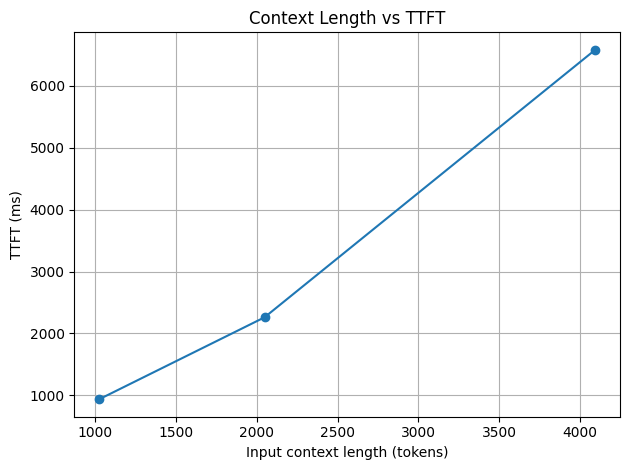

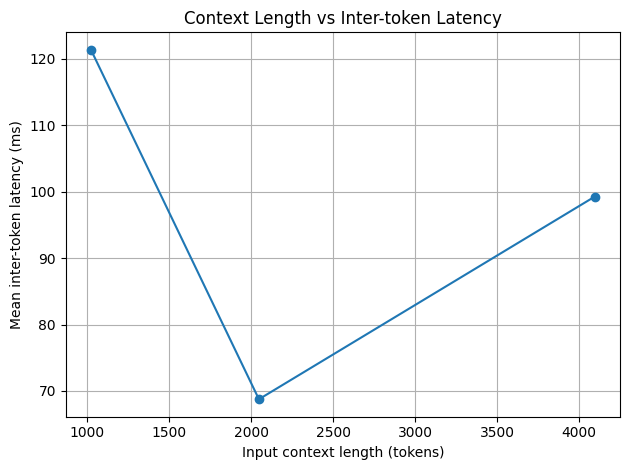

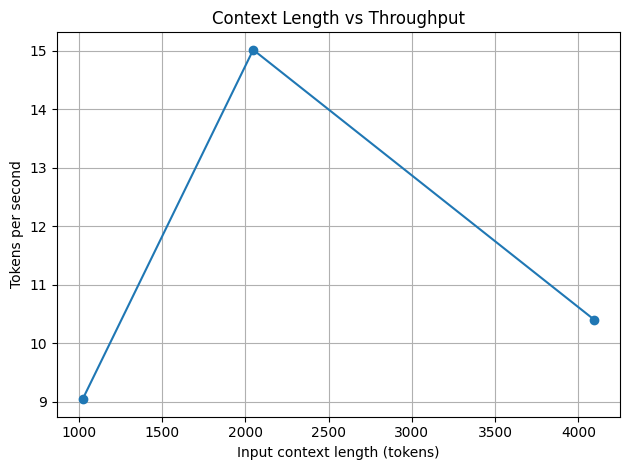

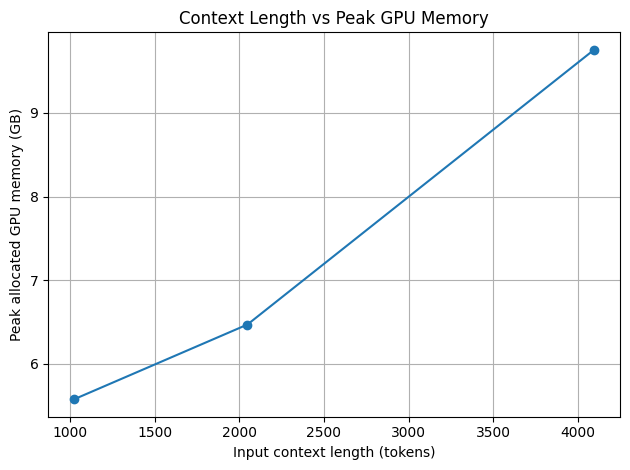

In [8]:
import matplotlib.pyplot as plt

df = pd.read_csv("/content/profiling_results.csv")
successful = df[df["status"] == "success"].copy()

if successful.empty:
    print("No successful measurements to plot.")
else:
    summary = successful.groupby("context_length", as_index=False).agg(
        ttft_ms=("ttft_ms", "mean"),
        inter_token_ms=("mean_inter_token_ms", "mean"),
        throughput=("throughput_tokens_per_sec", "mean"),
        peak_vram_gb=("peak_allocated_gb", "mean"),
        reserved_vram_gb=("peak_reserved_gb", "mean"),
    )

    display(summary)

    plots = [
        ("context_length", "ttft_ms",
         "Context Length vs TTFT", "TTFT (ms)",
         "ttft_vs_context.png"),
        ("context_length", "inter_token_ms",
         "Context Length vs Inter-token Latency",
         "Mean inter-token latency (ms)",
         "latency_vs_context.png"),
        ("context_length", "throughput",
         "Context Length vs Throughput",
         "Tokens per second", "throughput_vs_context.png"),
        ("context_length", "peak_vram_gb",
         "Context Length vs Peak GPU Memory",
         "Peak allocated GPU memory (GB)",
         "vram_vs_context.png"),
    ]

    for x, y, title, ylabel, filename in plots:
        plt.figure()
        plt.plot(summary[x], summary[y], marker="o")
        plt.xlabel("Input context length (tokens)")
        plt.ylabel(ylabel)
        plt.title(title)
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(f"/content/{filename}", dpi=150)
        plt.show()

    summary.to_csv("/content/profiling_summary.csv", index=False)
